# Bab 12 — Cross-Validation and Model Evaluation Techniques

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt, 2025)

---

## Ringkasan Bab

Tujuan machine learning adalah **generalisasi**: performa yang baik pada data yang belum pernah dilihat. Skor pada data latih tidak bisa dipercaya, dan satu kali train/test split bisa beruntung atau sial. Bab ini membahas cara mengestimasi performa secara jujur dan memilih model tanpa "mengintip" data uji. Banyak teknik di sini sudah dipakai sejak Bab 1; bab ini membahasnya secara sistematis.

| No | Resep | Alat scikit-learn | Inti |
|----|-------|-------------------|------|
| 1 | K-fold dan stratified k-fold | `KFold`, `StratifiedKFold` | estimasi performa dari beberapa pembagian data |
| 2 | Metode CV lanjutan | `LeaveOneOut`, nested CV | memaksimalkan data kecil; tuning tanpa bias |
| 3 | Implementasi CV di scikit-learn | `cross_val_score`, `cross_validate`, `GridSearchCV` | API tingkat tinggi, banyak metrik sekaligus |
| 4 | Teknik pemilihan model | `GridSearchCV`, `RandomizedSearchCV` | pencarian hyperparameter menyeluruh vs acak |
| 5 | Mengevaluasi kemampuan generalisasi | `learning_curve`, `validation_curve` | diagnosis bias vs varians |
| 6 | Latihan | | |

In [1]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd

## Resep 1 — K-Fold dan Stratified K-Fold

### Teori
Yang ingin kita ketahui adalah **galat generalisasi** (*expected risk*):
$$R(f) = \mathbb E_{(\mathbf x, y)\sim P}\big[L(y, f(\mathbf x))\big]$$
yaitu rata-rata kerugian pada data baru dari distribusi yang sama. Distribusi $P$ tidak diketahui, sehingga $R(f)$ diestimasi dari data yang **tidak dipakai melatih** model.

**K-fold cross-validation** membagi data menjadi $k$ bagian (*fold*) $D_1,\dots,D_k$. Untuk setiap $j$, model dilatih pada semua fold kecuali $D_j$, lalu diuji pada $D_j$:
$$\widehat{\text{CV}}_{(k)} = \frac1k\sum_{j=1}^{k}\text{skor}\big(f^{(-j)}, D_j\big)$$
Setiap sampel dipakai tepat satu kali sebagai data validasi. Rata-rata skor adalah estimasi performa; simpangan bakunya menggambarkan **stabilitas** model terhadap perubahan data.

**Pilihan $k$ dan trade-off bias–varians estimator:**
- $k$ kecil (misal 2–3): model dilatih pada data yang jauh lebih sedikit → estimasi cenderung **pesimis** (bias).
- $k$ besar (misal $n$): bias kecil, tetapi model antar-fold hampir identik sehingga skornya saling berkorelasi → estimasi bisa ber**varians** tinggi, dan komputasinya mahal.
- $k = 5$ atau $10$ adalah kompromi yang umum.

**Stratified k-fold** memastikan proporsi kelas di setiap fold sama dengan proporsi di keseluruhan data. Ini penting untuk data tidak seimbang: dengan k-fold biasa, satu fold bisa saja kekurangan sampel kelas minoritas sehingga skornya tidak representatif. Untuk klasifikasi, `cross_val_score(..., cv=5)` secara default sudah memakai `StratifiedKFold`.

**Varian lain:** `GroupKFold` (sampel dari kelompok yang sama — misalnya pasien yang sama — tidak boleh terpecah di latih dan uji), `TimeSeriesSplit` (data deret waktu: hanya boleh memakai masa lalu untuk memprediksi masa depan), `RepeatedStratifiedKFold` (mengulang k-fold dengan pengacakan berbeda untuk estimasi yang lebih stabil).

In [2]:
# Load the libraries
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Load the dataset
X, y = make_classification(n_samples=500, n_features=10, n_informative=8,
                           n_redundant=2, n_classes=2, random_state=2024)

In [3]:
# Initialize the k-fold cross-validator
kf = KFold(n_splits=5, shuffle=True, random_state=2024)

# Iterate through the folds and evaluate
accuracies = []
for train_index, test_index in kf.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    model = LogisticRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracies.append(accuracy_score(y_test, y_pred))
print(f"Average accuracy (KFold): {np.mean(accuracies):.3f}")

# Use stratified k-fold for balanced class splits
strat_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)
strat_accuracies = []
for train_index, test_index in strat_kf.split(X, y):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    model = LogisticRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    strat_accuracies.append(accuracy_score(y_test, y_pred))
print(f"Average accuracy (StratifiedKFold): {np.mean(strat_accuracies):.3f}")

Average accuracy (KFold): 0.756
Average accuracy (StratifiedKFold): 0.766


In [4]:
print('Skor per fold KFold          :', np.round(accuracies, 3), '| std = %.3f' % np.std(accuracies))
print('Skor per fold StratifiedKFold:', np.round(strat_accuracies, 3), '| std = %.3f' % np.std(strat_accuracies))
print('Proporsi kelas 1 keseluruhan : %.3f' % y.mean())
print('Proporsi kelas 1 per fold uji (KFold)     :', [round(float(y[te].mean()), 3) for _, te in kf.split(X)])
print('Proporsi kelas 1 per fold uji (Stratified):', [round(float(y[te].mean()), 3) for _, te in strat_kf.split(X, y)])

Skor per fold KFold          : [0.72 0.72 0.88 0.71 0.75] | std = 0.063
Skor per fold StratifiedKFold: [0.79 0.76 0.76 0.76 0.76] | std = 0.012
Proporsi kelas 1 keseluruhan : 0.500
Proporsi kelas 1 per fold uji (KFold)     : [0.52, 0.47, 0.54, 0.51, 0.46]
Proporsi kelas 1 per fold uji (Stratified): [0.5, 0.5, 0.5, 0.5, 0.5]


**Interpretasi.**
- Rata-rata akurasi KFold 0,756 dan StratifiedKFold 0,766 — hampir sama. Data ini **seimbang** (50% kelas 1), sehingga KFold biasa pun menghasilkan fold dengan proporsi kelas 0,46–0,54, tidak jauh dari 0,5. Pada data seimbang, stratifikasi tidak banyak berpengaruh pada rata-rata.
- Yang menarik adalah **sebaran** skornya: KFold berkisar 0,71–0,88 (std 0,063), sedangkan StratifiedKFold 0,76–0,79 (std 0,012). Fold ketiga KFold mendapat 0,88 — fold yang kebetulan "mudah". Inilah alasan utama memakai CV dan melaporkan simpangan bakunya: satu split tunggal bisa memberi angka antara 0,71 dan 0,88 untuk model yang **sama**.
- Akurasi ≈ 0,76 relatif rendah untuk data sintetis karena `make_classification` default menambahkan 1% *label noise* (`flip_y=0.01`) dan setiap kelas terdiri dari 2 cluster (`n_clusters_per_class=2`) sehingga tidak bisa dipisahkan secara sempurna oleh batas linear.

## Resep 2 — Metode Cross-Validation Lanjutan

### Teori

**Leave-One-Out CV (LOOCV)** = k-fold dengan $k = n$: setiap kali hanya satu sampel yang ditahan. Hampir tidak bias (model dilatih pada $n-1$ sampel), tetapi membutuhkan $n$ kali pelatihan, dan setiap skor fold dihitung dari **satu** sampel saja — sehingga metrik seperti akurasi atau $R^2$ per fold tidak bermakna; yang dipakai biasanya MSE atau akurasi rata-rata. Untuk model linear seperti Ridge ada rumus tertutup LOOCV yang efisien (dipakai oleh `RidgeCV`).

**Nested cross-validation.** Jika hyperparameter dipilih dengan CV, lalu skor CV terbaik yang sama dilaporkan sebagai estimasi performa, estimasinya **terlalu optimistis**: kita memilih konfigurasi yang kebetulan paling cocok dengan fold-fold tersebut (*selection bias*). Nested CV memisahkan dua tugas:
- **Loop dalam** (`GridSearchCV(..., cv=5)`): memilih hyperparameter memakai data latih dari fold luar saja.
- **Loop luar** (`cross_val_score(..., cv=5)`): mengevaluasi seluruh *prosedur* (termasuk tuning) pada fold yang tidak pernah dilihat loop dalam.

Total pelatihan = $k_{\text{luar}}\times k_{\text{dalam}}\times|\text{grid}|$ (di sini 5 × 5 × 5 = 125, plus refit). Yang diestimasi nested CV adalah performa **prosedur pembuatan model**, bukan satu model tertentu.

### Persiapan — dataset Diabetes
442 pasien, 10 fitur (umur, jenis kelamin, BMI, tekanan darah, 6 hasil pemeriksaan darah; sudah terpusat dan diskalakan), target = ukuran perkembangan penyakit satu tahun kemudian.

In [5]:
# Load the libraries
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import LeaveOneOut, GridSearchCV, cross_val_score
from sklearn.linear_model import Ridge

# Load the dataset
data = load_diabetes()
X = data.data
y = data.target

In [6]:
# Apply Leave-One-Out cross-validation with MSE scoring
loo = LeaveOneOut()
model = Ridge(alpha=1.0)
scores = cross_val_score(model, X, y, cv=loo, scoring="neg_mean_squared_error")
print(f"LOOCV mean MSE: {-np.mean(scores):.3f}")

# Define a grid for hyperparameter tuning
param_grid = {"alpha": [0.01, 0.1, 1, 10, 100]}

# Apply nested cross-validation using GridSearchCV (default scoring is fine for outer CV)
nested_scores = cross_val_score(
    GridSearchCV(Ridge(), param_grid, cv=5), X, y, cv=5
)
print(f"Nested CV mean score: {np.mean(nested_scores):.3f}")

LOOCV mean MSE: 3327.655
Nested CV mean score: 0.480


In [7]:
print('Jumlah fold LOOCV            :', len(scores))
print('Varians target (MSE baseline): %.1f' % np.var(y))
print('R^2 setara dari MSE LOOCV    : %.3f' % (1 - (-np.mean(scores)) / np.var(y)))
print('Skor R^2 per fold luar nested:', np.round(nested_scores, 3))

# Hyperparameter mana yang dipilih di setiap fold luar?
from sklearn.model_selection import cross_validate
nested = cross_validate(GridSearchCV(Ridge(), param_grid, cv=5), X, y, cv=5, return_estimator=True)
print('alpha terpilih per fold luar :', [est.best_params_['alpha'] for est in nested['estimator']])

# Bandingkan dengan skor CV terbaik non-nested (estimasi yang terlalu optimistis)
gs = GridSearchCV(Ridge(), param_grid, cv=5).fit(X, y)
print('Skor CV terbaik non-nested   : %.3f (alpha = %s)' % (gs.best_score_, gs.best_params_['alpha']))

Jumlah fold LOOCV            : 442
Varians target (MSE baseline): 5929.9
R^2 setara dari MSE LOOCV    : 0.439
Skor R^2 per fold luar nested: [0.411 0.52  0.492 0.44  0.537]
alpha terpilih per fold luar : [0.1, 0.01, 0.1, 0.1, 0.1]


Skor CV terbaik non-nested   : 0.481 (alpha = 0.01)


**Interpretasi.**
- **LOOCV:** 442 kali pelatihan (satu per pasien). MSE rata-rata 3.327,7, sedangkan varians target 5.929,9. Setara dengan $R^2 \approx 1 - 3327{,}7/5929{,}9 \approx 0{,}44$: Ridge menjelaskan sekitar 44% variasi perkembangan penyakit. Angka ini sesuai dengan reputasi dataset Diabetes yang memang sulit diprediksi dengan model linear.
- **Nested CV:** skor default `Ridge.score` adalah $R^2$. Rata-rata $R^2$ = 0,480, dengan rentang antar-fold 0,41–0,54. `alpha` yang dipilih loop dalam bisa berbeda antar-fold luar (di sini 0,1 pada empat fold dan 0,01 pada satu fold) — itulah sebabnya nested CV menilai **prosedur** tuning, bukan satu nilai `alpha`.
- Skor CV terbaik **non-nested** = 0,481, hampir sama dengan nested (0,480). Bias seleksi di sini kecil karena grid hanya berisi 5 nilai dan Ridge adalah model yang stabil (nilai `alpha` kecil memberi skor yang mirip). Pada grid besar dengan model yang fleksibel (misalnya SVM atau boosting dengan puluhan kombinasi), selisih antara skor non-nested dan nested bisa jauh lebih besar.
- Catatan: LOOCV di sini memakai MSE, sedangkan nested CV memakai $R^2$; kedua angka tidak bisa dibandingkan langsung kecuali dikonversi seperti di atas.

## Resep 3 — Implementasi Cross-Validation di scikit-learn

### Teori
Tiga tingkat API:

| Fungsi | Kegunaan |
|---|---|
| `cross_val_score(model, X, y, cv, scoring)` | satu metrik, mengembalikan array skor per fold |
| `cross_validate(..., scoring=[...])` | banyak metrik sekaligus, plus waktu `fit`/`score`, opsional skor latih (`return_train_score=True`) dan model per fold |
| `GridSearchCV` | CV untuk setiap kombinasi hyperparameter, lalu *refit* model terbaik pada seluruh data |

Parameter `scoring` menerima nama metrik (`'accuracy'`, `'f1'`, `'roc_auc'`, `'neg_mean_squared_error'`, ...). Untuk metrik kerugian, scikit-learn memakai versi **negatif** agar konvensinya selalu "makin besar makin baik".

### Persiapan
Data sintetis 500 sampel dengan kelas tidak seimbang: 70% kelas 0, 30% kelas 1.

In [8]:
# Load the libraries
import numpy as np
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, cross_validate, GridSearchCV

# Load and prepare the dataset
X, y = make_classification(n_samples=500, n_features=10, weights=[0.7, 0.3], random_state=2024)

In [9]:
# Use cross_val_score() to compute average accuracy
model = LogisticRegression()
scores = cross_val_score(model, X, y, cv=5, scoring='accuracy')
print(f"Mean accuracy: {np.mean(scores):.3f}")

# Use cross_validate() to compute multiple metrics
results = cross_validate(model, X, y, cv=5,
                         scoring=['accuracy', 'precision', 'recall', 'f1'])
print(f"Mean precision: {np.mean(results['test_precision']):.3f}")
print(f"Mean recall: {np.mean(results['test_recall']):.3f}")
print(f"Mean F1: {np.mean(results['test_f1']):.3f}")

# Use GridSearchCV() for hyperparameter tuning with cross-validation
param_grid = {"C": [0.01, 0.1, 1, 10]}
grid = GridSearchCV(LogisticRegression(), param_grid, cv=5, scoring='accuracy')
grid.fit(X, y)
print(f"Best hyperparameter (C): {grid.best_params_['C']}")
print(f"Best accuracy: {grid.best_score_:.3f}")

Mean accuracy: 0.910
Mean precision: 0.875
Mean recall: 0.820
Mean F1: 0.845
Best hyperparameter (C): 0.1
Best accuracy: 0.918


In [10]:
print('Proporsi kelas 1: %.2f' % y.mean())
print('Akurasi baseline (selalu menebak kelas 0): %.3f' % (1 - y.mean()))
print('Waktu fit rata-rata per fold: %.4f detik' % np.mean(results['fit_time']))
print('Skor CV per C:', dict(zip(param_grid['C'], np.round(grid.cv_results_['mean_test_score'], 3).tolist())))

Proporsi kelas 1: 0.30
Akurasi baseline (selalu menebak kelas 0): 0.700
Waktu fit rata-rata per fold: 0.0023 detik
Skor CV per C: {0.01: 0.894, 0.1: 0.918, 1: 0.91, 10: 0.908}


**Interpretasi.**
- Akurasi rata-rata 0,910 terdengar tinggi, tetapi baseline yang selalu menebak kelas mayoritas sudah memperoleh 0,700. Jadi model menaikkan akurasi sebesar 21 poin persentase di atas tebakan naif — itulah ukuran yang lebih jujur.
- `cross_validate` memperlihatkan detail yang tidak terlihat dari akurasi: **recall kelas 1 = 0,820**, artinya sekitar 18% sampel kelas minoritas tidak tertangkap, sedangkan precision 0,875. Pada data tidak seimbang, F1 (0,845) lebih representatif daripada akurasi.
- `GridSearchCV` memilih `C = 0.1` dengan akurasi CV 0,918, sedikit lebih baik daripada default `C = 1` (0,910).
- **Catatan metodologis:** di resep ini `GridSearchCV` di-fit pada **seluruh** data, sehingga skor 0,918 adalah estimasi yang sedikit optimistis (lihat nested CV di Resep 2). Resep berikutnya memperbaikinya dengan memisahkan data uji terlebih dahulu.

## Resep 4 — Teknik Pemilihan Model

### Teori
**Grid search** mencoba semua kombinasi; jumlahnya tumbuh **eksponensial** terhadap jumlah hyperparameter (5 parameter × 10 nilai = 100.000 kombinasi).

**Randomized search** (Bergstra & Bengio, 2012) mengambil `n_iter` kombinasi secara acak dari **distribusi** yang ditentukan. Alasan keefektifannya: biasanya hanya sedikit hyperparameter yang benar-benar berpengaruh. Grid 3×3 hanya mencoba 3 nilai unik per parameter, sedangkan 9 sampel acak mencoba 9 nilai unik per parameter. Peluang bahwa minimal satu dari $m$ sampel acak jatuh di 5% konfigurasi terbaik adalah $1 - 0{,}95^m$ — untuk $m = 60$ sudah ≈ 95%.

Untuk hyperparameter yang skalanya mencakup beberapa orde besaran (seperti `C` atau `alpha`), gunakan distribusi **log-uniform**: $\log C \sim \mathcal U(\log a, \log b)$, sehingga $10^{-3}$–$10^{-2}$ mendapat porsi sampel yang sama dengan $10$–$100$.

Alur kerja yang benar:
1. Pisahkan **data uji** dan jangan disentuh.
2. Lakukan pencarian hyperparameter dengan CV pada **data latih**.
3. Evaluasi model akhir **sekali** pada data uji.

Alternatif yang lebih efisien: `HalvingGridSearchCV` / `HalvingRandomSearchCV` (*successive halving*) dan optimasi Bayesian (misalnya Optuna).

In [11]:
# Load the libraries
import numpy as np
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, train_test_split
from sklearn.metrics import accuracy_score

# Load and split the dataset
X, y = make_classification(n_samples=500, n_features=10, weights=[0.7, 0.3], random_state=2024)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

In [12]:
# Use GridSearchCV to evaluate all combinations in the parameter grid
param_grid = {"C": [0.001, 0.01, 0.1, 1, 10, 100]}
grid = GridSearchCV(LogisticRegression(), param_grid, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)
print(f"GridSearchCV best C: {grid.best_params_['C']}")

# Use RandomizedSearchCV to evaluate a random sample of parameters
from scipy.stats import loguniform
param_dist = {"C": loguniform(1e-3, 1e2)}
random_search = RandomizedSearchCV(LogisticRegression(), param_distributions=param_dist,
                                    n_iter=10, cv=5, scoring='accuracy', random_state=2024)
random_search.fit(X_train, y_train)
print(f"RandomizedSearchCV best C: {random_search.best_params_['C']:.4f}")

# Evaluate final model performance
final_model = random_search.best_estimator_
y_pred = final_model.predict(X_test)
print(f"Final accuracy on test set: {accuracy_score(y_test, y_pred):.3f}")

GridSearchCV best C: 0.1


RandomizedSearchCV best C: 0.1744
Final accuracy on test set: 0.940


In [13]:
print('Skor CV GridSearch per C:', dict(zip(param_grid['C'], np.round(grid.cv_results_['mean_test_score'], 3).tolist())))
print('Nilai C yang dicoba RandomizedSearch:', np.round(sorted(random_search.cv_results_['param_C'].data.astype(float)), 4))
print('Skor CV terbaik: Grid = %.3f | Random = %.3f' % (grid.best_score_, random_search.best_score_))
print('Akurasi uji model GridSearch: %.3f' % accuracy_score(y_test, grid.predict(X_test)))

Skor CV GridSearch per C: {0.001: 0.694, 0.01: 0.877, 0.1: 0.894, 1: 0.886, 10: 0.889, 100: 0.889}
Nilai C yang dicoba RandomizedSearch: [1.7000e-03 3.4000e-03 8.7000e-03 1.0600e-02 1.7440e-01 2.3400e-01
 8.7110e-01 2.4946e+00 3.1300e+00 4.3271e+00]
Skor CV terbaik: Grid = 0.894 | Random = 0.897
Akurasi uji model GridSearch: 0.933


**Interpretasi.**
- **GridSearchCV** mencoba 6 nilai `C`; yang terbaik `C = 0.1` (CV 0,894). Perhatikan pola skornya: `C = 0.001` hanya 0,694 (lebih rendah dari baseline 0,70 — regularisasi terlalu kuat, model hampir hanya memprediksi kelas mayoritas), lalu skor naik cepat dan stabil di sekitar 0,88–0,89 untuk `C ≥ 0.01`.
- **RandomizedSearchCV** mengambil 10 nilai dari distribusi log-uniform $[10^{-3}, 10^{2}]$. Nilai-nilainya tersebar merata di skala log (0,0017 sampai 4,3), dan nilai terbaiknya `C ≈ 0.174` (CV 0,897) — sedikit lebih baik daripada grid, karena randomized search bisa mencoba nilai di **antara** titik-titik grid.
- Akurasi data uji model akhir = 0,940 (dan model grid = 0,933). Kedua model hampir setara; dengan 150 sampel uji, selisih 0,007 = 1 sampel.
- Di sini data uji benar-benar terpisah dari proses tuning, sehingga 0,94 adalah estimasi yang jujur. Data uji ternyata sedikit "lebih mudah" daripada rata-rata fold CV (≈0,89) — variasi wajar dari satu kali split.

## Resep 5 — Mengevaluasi Kemampuan Generalisasi

### Teori
Galat kuadrat yang diharapkan dapat diuraikan (**bias–variance decomposition**):
$$\mathbb E\big[(y-\hat f(\mathbf x))^2\big] = \underbrace{\big(\mathbb E[\hat f(\mathbf x)]-f(\mathbf x)\big)^2}_{\text{bias}^2} + \underbrace{\operatorname{Var}\big(\hat f(\mathbf x)\big)}_{\text{varians}} + \underbrace{\sigma^2}_{\text{noise}}$$
Model sederhana → bias tinggi (underfitting); model kompleks → varians tinggi (overfitting). Dua alat diagnosis:

**Learning curve** — skor latih dan validasi sebagai fungsi **ukuran data latih**:
| Pola | Diagnosis | Tindakan |
|---|---|---|
| Kedua kurva rendah dan berdekatan | bias tinggi (underfitting) | model lebih kompleks / fitur lebih baik; menambah data **tidak** membantu |
| Kurva latih tinggi, validasi jauh di bawah | varians tinggi (overfitting) | tambah data, regularisasi, model lebih sederhana |
| Keduanya tinggi dan bertemu | baik | – |

**Validation curve** — skor latih dan validasi sebagai fungsi **satu hyperparameter** (di sini `C`). Di sisi regularisasi kuat kedua skor rendah (underfit); di sisi regularisasi lemah skor latih terus naik sementara skor validasi turun (overfit). Titik optimum ada di puncak kurva validasi.

In [14]:
# Load the libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import learning_curve, validation_curve

# Load the dataset
X, y = make_classification(n_samples=1000, n_features=20, weights=[0.7, 0.3], random_state=2024)

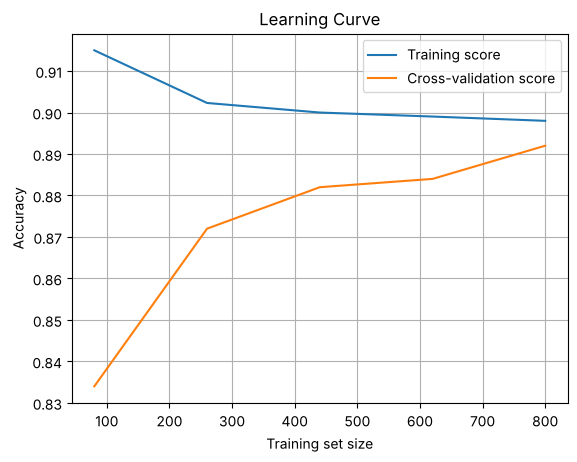

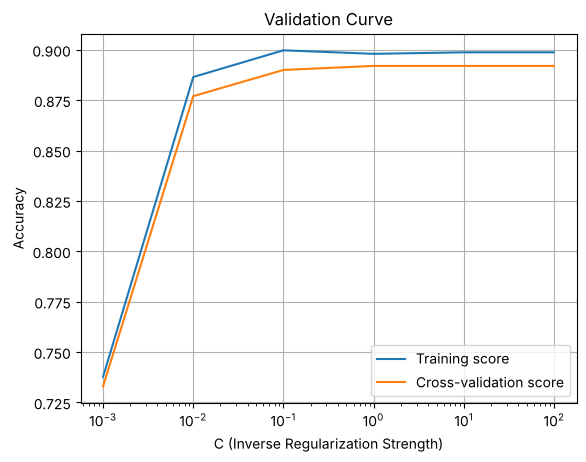

In [15]:
# Plot a learning curve
train_sizes, train_scores, test_scores = learning_curve(
    LogisticRegression(), X, y, cv=5, scoring='accuracy', train_sizes=np.linspace(0.1, 1.0, 5), random_state=2024)

train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

plt.plot(train_sizes, train_mean, label='Training score')
plt.plot(train_sizes, test_mean, label='Cross-validation score')
plt.xlabel('Training set size')
plt.ylabel('Accuracy')
plt.title('Learning Curve')
plt.legend()
plt.grid(True)
plt.show()

# Plot a validation curve
param_range = np.logspace(-3, 2, 6)
train_scores, test_scores = validation_curve(
    LogisticRegression(), X, y, param_name="C", param_range=param_range,
    cv=5, scoring='accuracy')

train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

plt.semilogx(param_range, train_mean, label='Training score')
plt.semilogx(param_range, test_mean, label='Cross-validation score')
plt.xlabel('C (Inverse Regularization Strength)')
plt.ylabel('Accuracy')
plt.title('Validation Curve')
plt.legend()
plt.grid(True)
plt.show()

In [16]:
lc_train, lc_test = np.mean(learning_curve(LogisticRegression(), X, y, cv=5, scoring='accuracy',
                                            train_sizes=np.linspace(0.1, 1.0, 5))[1:], axis=2)
for n_, a, b in zip(train_sizes, lc_train, lc_test):
    print(f'n_latih = {n_:4d} | skor latih = {a:.3f} | skor validasi = {b:.3f} | selisih = {a - b:.3f}')
print()
for c, a, b in zip(param_range, train_mean, test_mean):
    print(f'C = {c:8.3f} | skor latih = {a:.3f} | skor validasi = {b:.3f}')

n_latih =   80 | skor latih = 0.915 | skor validasi = 0.834 | selisih = 0.081
n_latih =  260 | skor latih = 0.902 | skor validasi = 0.872 | selisih = 0.030
n_latih =  440 | skor latih = 0.900 | skor validasi = 0.882 | selisih = 0.018
n_latih =  620 | skor latih = 0.899 | skor validasi = 0.884 | selisih = 0.015
n_latih =  800 | skor latih = 0.898 | skor validasi = 0.892 | selisih = 0.006

C =    0.001 | skor latih = 0.738 | skor validasi = 0.733
C =    0.010 | skor latih = 0.887 | skor validasi = 0.877
C =    0.100 | skor latih = 0.900 | skor validasi = 0.890
C =    1.000 | skor latih = 0.898 | skor validasi = 0.892
C =   10.000 | skor latih = 0.899 | skor validasi = 0.892
C =  100.000 | skor latih = 0.899 | skor validasi = 0.892


**Interpretasi.**

**Learning curve** — pola "model baik":
- Dengan 80 sampel latih, skor latih 0,915 dan validasi 0,834 (selisih 0,081 → ada sedikit overfitting karena data sedikit).
- Saat data latih bertambah menjadi 800, skor validasi naik ke 0,892 dan selisihnya menyusut ke 0,006. Kedua kurva **bertemu** di sekitar 0,89–0,90.
- Kurva yang sudah bertemu dan mendatar artinya menambah data **tidak akan** banyak menaikkan akurasi lagi. Batasnya sekarang adalah **bias** model linear (dan noise label), sehingga peningkatan berikutnya harus datang dari model atau fitur yang lebih kaya, bukan dari data tambahan.

**Validation curve** (`C` dari 0,001 sampai 100):
- `C = 0.001`: skor latih dan validasi sama-sama rendah (≈0,73–0,74) → **underfitting** akibat regularisasi terlalu kuat.
- `C ≥ 0.1`: kedua skor stabil di ≈0,89–0,90 dan selisihnya kecil.
- Tidak terlihat overfitting di sisi `C` besar: dengan 1.000 sampel dan hanya 20 fitur, regresi logistik tanpa regularisasi pun tidak cukup fleksibel untuk menghafal data. Overfitting di sisi kanan validation curve biasanya baru muncul pada model yang jauh lebih fleksibel atau data dengan fitur sangat banyak.

## Latihan Praktik

### Latihan 1 — Cross-validation regresi logistik dengan beberapa metrik

In [17]:
# Load libraries
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

# Load the dataset
X, y = make_classification(n_samples=500, n_features=10, random_state=2024)

# Cross-validate and collect metrics
model = LogisticRegression()
results = cross_validate(model, X, y, cv=5, scoring=["accuracy", "precision", "recall", "f1"])

for metric in ["test_accuracy", "test_precision", "test_recall", "test_f1"]:
    print(f"{metric}: {results[metric].mean():.3f}")

test_accuracy: 0.896
test_precision: 0.896
test_recall: 0.895
test_f1: 0.895


**Interpretasi.** Pada data seimbang (`make_classification` tanpa `weights`), accuracy, precision, recall, dan F1 semuanya ≈ 0,895–0,896. Jika kelas seimbang dan kesalahan tersebar merata di kedua arah, keempat metrik memang akan berdekatan. Bandingkan dengan Resep 3 (data 70:30): di sana recall (0,820) jauh di bawah akurasi (0,910). Ketidakseimbangan kelaslah yang membuat metrik-metrik ini berbeda.

### Latihan 2 — Tuning hyperparameter SVM dengan grid search

In [18]:
# Load libraries
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report

# Load and split the dataset
X, y = make_classification(n_samples=500, n_features=10, random_state=2024)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Perform grid search
param_grid = {"C": [0.1, 1, 10], "kernel": ["linear", "rbf"]}
grid = GridSearchCV(SVC(), param_grid, cv=5)
grid.fit(X_train, y_train)
print(f"Best parameters: {grid.best_params_}")

# Evaluate on the test set
y_pred = grid.predict(X_test)
print(classification_report(y_test, y_pred))

Best parameters: {'C': 0.1, 'kernel': 'rbf'}
              precision    recall  f1-score   support

           0       0.94      0.86      0.89        84
           1       0.84      0.92      0.88        66

    accuracy                           0.89       150
   macro avg       0.89      0.89      0.89       150
weighted avg       0.89      0.89      0.89       150



In [19]:
display(pd.DataFrame(grid.cv_results_)[['param_kernel', 'param_C', 'mean_test_score', 'std_test_score', 'rank_test_score']]
        .sort_values('rank_test_score').round(3))

,param_kernel,param_C,mean_test_score,std_test_score,rank_test_score
1,rbf,0.1,0.897,0.019,1
3,rbf,1.0,0.897,0.025,1
4,linear,10.0,0.897,0.025,1
0,linear,0.1,0.891,0.023,4
2,linear,1.0,0.891,0.021,4
5,rbf,10.0,0.854,0.028,6


**Interpretasi.** `GridSearchCV` melaporkan `C = 0.1, kernel = 'rbf'` sebagai yang terbaik, tetapi tabel memperlihatkan bahwa **tiga konfigurasi seri** di 0,897 (rbf `C=0.1`, rbf `C=1`, linear `C=10`) dengan std 0,02–0,025, dan konfigurasi linear lain hanya 0,006 di bawahnya. Selisih sekecil ini jauh di bawah simpangan baku antar-fold, sehingga secara statistik konfigurasi-konfigurasi ini **setara**. Satu-satunya yang jelas lebih buruk adalah rbf `C=10` (0,854) — tanda overfitting karena margin terlalu sempit. Pada kondisi seperti ini, pilih model paling sederhana (misalnya kernel linear) bila interpretasi atau kecepatan penting.

Pada data uji: akurasi 0,89; recall kelas 1 = 0,92 tetapi recall kelas 0 = 0,86 — model sedikit condong memprediksi kelas 1.

### Latihan 3 — Learning curve dan validation curve

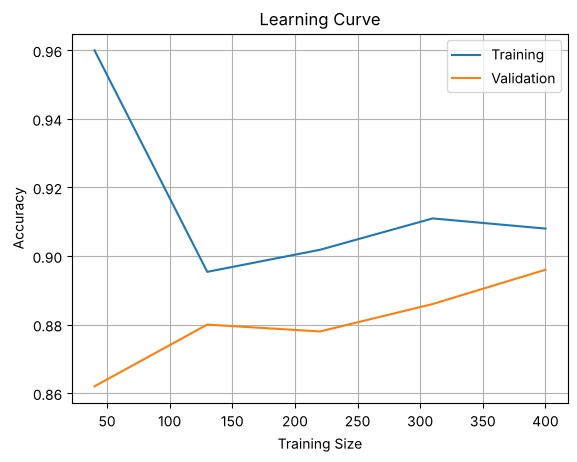

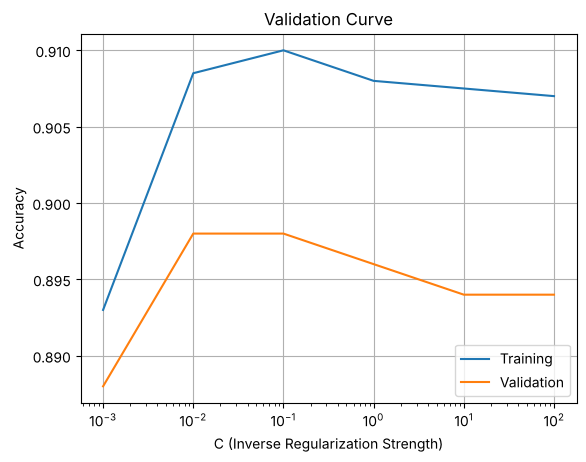

In [20]:
# Load libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, validation_curve

# Plot the learning curve
train_sizes, train_scores, test_scores = learning_curve(
    LogisticRegression(), X, y, cv=5, scoring='accuracy', train_sizes=np.linspace(0.1, 1.0, 5), random_state=2024)

plt.plot(train_sizes, train_scores.mean(axis=1), label="Training")
plt.plot(train_sizes, test_scores.mean(axis=1), label="Validation")
plt.title("Learning Curve")
plt.xlabel("Training Size")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Plot the validation curve
param_range = np.logspace(-3, 2, 6)
train_scores, test_scores = validation_curve(
    LogisticRegression(), X, y, param_name="C", param_range=param_range,
    cv=5, scoring='accuracy')

plt.semilogx(param_range, train_scores.mean(axis=1), label="Training")
plt.semilogx(param_range, test_scores.mean(axis=1), label="Validation")
plt.title("Validation Curve")
plt.xlabel("C (Inverse Regularization Strength)")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [21]:
for c, a, b in zip(param_range, train_scores.mean(axis=1), test_scores.mean(axis=1)):
    print(f'C = {c:8.3f} | latih = {a:.3f} | validasi = {b:.3f}')

C =    0.001 | latih = 0.893 | validasi = 0.888
C =    0.010 | latih = 0.908 | validasi = 0.898
C =    0.100 | latih = 0.910 | validasi = 0.898
C =    1.000 | latih = 0.908 | validasi = 0.896
C =   10.000 | latih = 0.907 | validasi = 0.894
C =  100.000 | latih = 0.907 | validasi = 0.894


**Interpretasi.** Kedua kurva untuk data latihan ini (500 sampel, 10 fitur, seimbang) memperlihatkan model yang **sehat**: skor latih dan validasi berdekatan (selisih ≈ 0,01) di hampir seluruh rentang `C`. Berbeda dengan Resep 5, bahkan `C = 0.001` masih memberi validasi 0,888. Pada data seimbang, regularisasi sangat kuat tidak "mendorong" model ke tebakan kelas mayoritas, karena tidak ada kelas mayoritas. Puncak validasi (0,898) di `C = 0.01–0.1`, tetapi seluruh kurva cukup datar — model ini **tidak sensitif** terhadap `C` pada data tersebut.

## Kesimpulan Bab 12

- **K-fold CV** memberi estimasi performa yang lebih andal daripada satu split; laporkan rata-rata **dan** simpangan bakunya. Gunakan **stratified** k-fold untuk klasifikasi (default di scikit-learn), `GroupKFold` untuk data berkelompok, `TimeSeriesSplit` untuk deret waktu.
- **LOOCV** memaksimalkan data latih tetapi mahal; **nested CV** memberi estimasi performa yang jujur ketika hyperparameter ikut di-tuning.
- `cross_val_score` (satu metrik), `cross_validate` (banyak metrik), dan `GridSearchCV`/`RandomizedSearchCV` (tuning) adalah API utamanya. Randomized search dengan distribusi log-uniform efisien untuk ruang hyperparameter yang besar.
- Pada data tidak seimbang, bandingkan akurasi dengan **baseline kelas mayoritas** dan perhatikan precision/recall/F1.
- **Learning curve** dan **validation curve** mendiagnosis underfitting vs overfitting dan menunjukkan apakah menambah data atau mengubah kompleksitas model akan membantu.
- Data uji hanya dipakai **sekali**, di akhir.